In [4]:
import sys
print ("version python:")
print(sys.version)
print ("\npercorso python:")
print(sys.executable)

version python:
3.13.1 (main, Feb 18 2026, 20:57:27) [Clang 21.0.0git (https:/github.com/llvm/llvm-project 2f05451198e2f222ec66cec489

percorso python:



In [1]:
%pip install "osmnx>=2,<3" "networkx>=3,<4" geopandas pandas numpy matplotlib scipy

In [8]:
pip install pandas

mambajs 0.21.4

Process pip requirements ...

Requirement pandas already handled by conda/micromamba/mamba.


In [2]:
import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point
from pathlib import Path

print("Import riusciti")
print("OSMnx:", ox.__version__)
print("NetworkX:", nx.__version__)
print("GeoPandas:", gpd.__version__)
print("Pandas:", pd.__version__)

Import riusciti
OSMnx: 2.2.0
NetworkX: 3.6.1
GeoPandas: 1.1.3
Pandas: 3.0.2


In [3]:
CENTRO = (45.0709, 7.6859)  # Piazza Castello (lat, lon)

DIST_RETE = 2600
DIST_POI = 2000

VELOCITA_KMH = 4.5
BETA = 0.10

OUTPUT = Path("risultati_torino")
OUTPUT.mkdir(exist_ok=True)

ox.settings.use_cache = True

print("Area di studio impostata")

Area di studio impostata


In [4]:
G = ox.graph_from_point(
    CENTRO,
    dist=DIST_RETE,
    network_type="walk"
)

Gm = ox.project_graph(G)

print("Numero di nodi:", len(Gm.nodes))
print("Numero di archi:", len(Gm.edges))
print("Sistema di coordinate:", Gm.graph["crs"])

Numero di nodi: 12302
Numero di archi: 37164
Sistema di coordinate: EPSG:32632


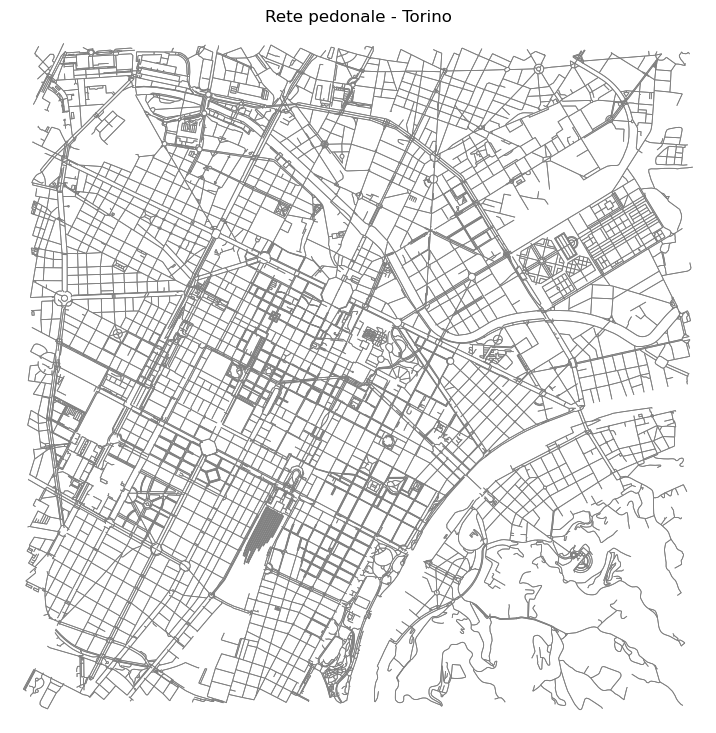

In [5]:
fig, ax = ox.plot_graph(
    Gm,
    node_size=0,
    edge_color="gray",
    edge_linewidth=0.6,
    bgcolor="white",
    figsize=(9, 9),
    show=False,
    close=False
)

ax.set_title("Rete pedonale - Torino")
plt.show()

In [6]:
farmacie = ox.features_from_point(
    CENTRO,
    tags={"amenity": "pharmacy"},
    dist=DIST_POI
)

farmacie = farmacie.loc[
    (farmacie["amenity"] == "pharmacy")
    & farmacie.geometry.notna()
    & ~farmacie.geometry.is_empty
].copy()

if farmacie.empty:
    raise RuntimeError("Nessuna farmacia trovata")

print("Farmacie trovate:", len(farmacie))

Farmacie trovate: 97


In [7]:
farmacie = farmacie.to_crs(
    Gm.graph["crs"]
).reset_index(drop=True)

farmacie["id_poi"] = [
    f"F{i+1:03d}"
    for i in range(len(farmacie))
]

farmacie["punto"] = (
    farmacie.geometry.representative_point()
)

farmacie["nodo"] = ox.distance.nearest_nodes(
    Gm,
    X=farmacie["punto"].x.to_numpy(),
    Y=farmacie["punto"].y.to_numpy()
)

farmacie_punti = farmacie.set_geometry("punto")

display(farmacie[["id_poi", "nodo"]].head())

,id_poi,nodo
0,F001,11281834068
1,F002,6843951500
2,F003,7133462212
3,F004,3357498194
4,F005,320908396


In [11]:
centro_proiettato = gpd.GeoSeries(
    [Point(CENTRO[1], CENTRO[0])],
    crs="EPSG:4326"
).to_crs(Gm.graph["crs"]).iloc[0]

offsets = np.linspace(-700, 700, 5)

coordinate_origini = [
    (
        centro_proiettato.x + dx,
        centro_proiettato.y + dy
    )
    for dx in offsets
    for dy in offsets
]

nodi_candidati = ox.distance.nearest_nodes(
    Gm,
    X=[xy[0] for xy in coordinate_origini],
    Y=[xy[1] for xy in coordinate_origini]
)

nodi_origine = list(dict.fromkeys(nodi_candidati))

In [12]:
origini = gpd.GeoDataFrame(
    {
        "id_origine": [
            f"O{i+1:02d}"
            for i in range(len(nodi_origine))
        ],
        "nodo": nodi_origine
    },
    geometry=[
        Point(Gm.nodes[n]["x"], Gm.nodes[n]["y"])
        for n in nodi_origine
    ],
    crs=Gm.graph["crs"]
)

print("Origini distinte:", len(origini))
display(origini.head())

Origini distinte: 25


,id_origine,nodo,geometry
0,O01,308747156,POINT (395859.408 4990978.8)
1,O02,2284406992,POINT (395862.126 4991297.299)
2,O03,2068672472,POINT (395847.428 4991664.952)
3,O04,5995173805,POINT (395846.596 4992032.489)
4,O05,1118464903,POINT (395851.383 4992366.578)


In [10]:
metri_al_minuto = VELOCITA_KMH * 1000 / 60

for u, v, k, attributi in Gm.edges(
    keys=True,
    data=True
):
    attributi["tempo_min"] = (
        float(attributi["length"])
        / metri_al_minuto
    )

print("Tempi assegnati agli archi")

Tempi assegnati agli archi


In [13]:
righe = []

for id_origine, nodo_origine in zip(
    origini["id_origine"],
    origini["nodo"]
):

    costi = nx.single_source_dijkstra_path_length(
        Gm,
        nodo_origine,
        weight="tempo_min"
    )

    for id_poi, nodo_poi in zip(
        farmacie["id_poi"],
        farmacie["nodo"]
    ):

        righe.append({
            "id_origine": id_origine,
            "id_poi": id_poi,
            "tempo_min": costi.get(nodo_poi, np.inf)
        })

matrice = pd.DataFrame(righe)

display(matrice.head(10))

,id_origine,id_poi,tempo_min
0,O01,F001,30.197475
1,O01,F002,25.841392
2,O01,F003,32.554458
3,O01,F004,4.669755
4,O01,F005,52.889387
5,O01,F006,16.209848
6,O01,F007,24.822603
7,O01,F008,43.096989
8,O01,F009,18.231353
9,O01,F010,11.987266


In [14]:
calcolo = matrice.copy()

# Opportunità cumulative
calcolo["entro_10"] = calcolo["tempo_min"] <= 10
calcolo["entro_15"] = calcolo["tempo_min"] <= 15

# Accessibilità gravitazionale
calcolo["contributo_gravita"] = np.exp(
    -BETA * calcolo["tempo_min"]
)

# Aggregazione per origine
risultati = (
    calcolo.groupby("id_origine", as_index=False)
    .agg(
        tempo_minimo_min=("tempo_min", "min"),
        farmacie_entro_10_min=("entro_10", "sum"),
        farmacie_entro_15_min=("entro_15", "sum"),
        indice_gravitazionale=(
            "contributo_gravita", "sum"
        )
    )
)

risultati["tempo_minimo_min"] = (
    risultati["tempo_minimo_min"]
    .replace(np.inf, np.nan)
)

display(risultati.round(3))

,id_origine,tempo_minimo_min,farmacie_entro_10_min,farmacie_entro_15_min,indice_gravitazionale
0,O01,1.482,15,33,18.835
1,O02,3.964,20,34,18.765
2,O03,0.964,15,31,19.455
3,O04,0.861,15,24,17.666
4,O05,4.125,10,22,14.295
5,O06,3.316,18,34,19.594
6,O07,1.708,14,35,19.223
7,O08,1.056,20,33,21.525
8,O09,1.170,18,27,18.574
9,O10,1.124,7,24,15.009


<ipython-input-15-ba84e950f0c4>:44: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(
<ipython-input-15-ba84e950f0c4>:44: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(


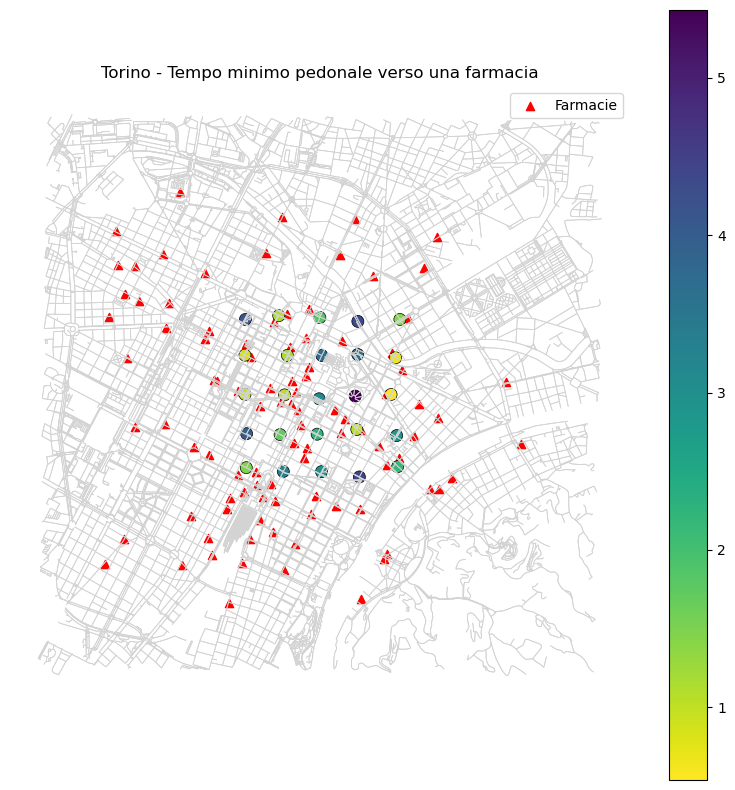

In [15]:
origini_risultati = origini.merge(
    risultati,
    on="id_origine"
)

archi = ox.graph_to_gdfs(
    Gm,
    nodes=False
)

fig, ax = plt.subplots(figsize=(10, 10))

archi.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.6
)

farmacie_punti.plot(
    ax=ax,
    color="red",
    marker="^",
    markersize=35,
    label="Farmacie"
)

origini_risultati.plot(
    ax=ax,
    column="tempo_minimo_min",
    cmap="viridis_r",
    legend=True,
    markersize=75,
    edgecolor="black",
    linewidth=0.5
)

ax.set_title(
    "Torino - Tempo minimo pedonale verso una farmacia"
)

ax.set_axis_off()
ax.legend(loc="upper right")

fig.savefig(
    OUTPUT / "mappa_tempo_minimo.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [16]:
coppie_valide = matrice.loc[
    np.isfinite(matrice["tempo_min"])
    & (matrice["tempo_min"] > 0)
]

coppia = coppie_valide.iloc[0]

nodo_o = origini.set_index("id_origine").loc[
    coppia["id_origine"], "nodo"
]

nodo_p = farmacie.set_index("id_poi").loc[
    coppia["id_poi"], "nodo"
]

percorso = nx.shortest_path(
    Gm,
    nodo_o,
    nodo_p,
    weight="tempo_min"
)

tempo_verifica = nx.shortest_path_length(
    Gm,
    nodo_o,
    nodo_p,
    weight="tempo_min"
)

print("Tempo calcolato:", round(tempo_verifica, 2))
print("Tempo nella matrice:", round(coppia["tempo_min"], 2))

assert np.isclose(
    tempo_verifica,
    coppia["tempo_min"]
)

Tempo calcolato: 30.2
Tempo nella matrice: 30.2


In [17]:
matrice.replace(
    [np.inf, -np.inf], np.nan
).to_csv(
    OUTPUT / "matrice_origine_destinazione.csv",
    index=False
)

risultati.to_csv(
    OUTPUT / "metriche_accessibilita.csv",
    index=False
)

origini_risultati.to_crs(
    "EPSG:4326"
).to_file(
    OUTPUT / "origini_con_metriche.geojson",
    driver="GeoJSON"
)

print("Risultati salvati in:", OUTPUT.resolve())

Risultati salvati in: /drive/notebooks/risultati_torino
